In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from tabulate import tabulate
import matplotlib.pyplot as plt
import scipy.stats as st

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

In [ ]:
KONDINSKY_PREFIX = "K"
ISHIM_PREFIX = "I"

DATA_DIR = Path("/content/drive/MyDrive/data")
PRIVATE_DATA_DIR = DATA_DIR / "private"

# Загрузка и предобработка данных

Попробуем прочитать исходные данные

Ишимский район

In [ ]:
ishim_table = pd.read_parquet(PRIVATE_DATA_DIR / "ishim.parquet.gzip")

In [ ]:
ishim_table.dtypes

Orders_ID                   int64
RequestId                   int64
SampleId                    int64
LaboratoryId              float64
OrganizationId              int64
BiomaterialId               int64
DateTimeSampling           object
CountBiomaterial            int64
NameUnit                  float64
PatientId                  object
Surname                    object
Name_                      object
Patronymic                 object
Birthday                   object
Sex                       float64
HospitalDepartmentId       object
HospitalDepartmentName     object
DoctorId                  float64
DoctorFullName             object
DiagnosisCode              object
TestId                     object
Mnemonic                   object
TestName                   object
QuantResult                object
QualResult                 object
UnitName                   object
BoundRefer                 object
Comment                    object
DateTime                   object
dtype: object

Кондинский район

In [ ]:
files_for_kondinsky = (PRIVATE_DATA_DIR / "kondinsky").glob("**/*.parquet.gzip")
dfs_for_kondinsky = []
for file in files_for_kondinsky:
  df = pd.read_parquet(file)
  dfs_for_kondinsky.append(df)
kondinsky_table = pd.concat(dfs_for_kondinsky, ignore_index=True)

In [ ]:
kondinsky_table

,Лок. Номер,№ карты,Дата рождения,Пол,Национальность,№ анализа,Дата направления,Тип,Предварительный диагноз,Окончательный диагноз,Отделение,Наименование анализа,Наименование теста,Результат,№ случая,№ теста
0,1792267,4046.0,1955-10-23,М,РУССКИЕ,8,2019-01-16 08:26:37,1.0,K57.3,K52.3,Хирургическое отделение_стац,Общий (клинический) анализ крови развернутый,Сегментоядерные,35.4,NaN,NaN
1,1792267,4046.0,1955-10-23,М,РУССКИЕ,8,2019-01-16 08:26:37,1.0,K57.3,K52.3,Хирургическое отделение_стац,Общий (клинический) анализ крови развернутый,Тромбоциты,277.0,NaN,NaN
2,2127984,3836.0,2004-01-21,М,None,18,2019-01-14 08:15:27,7.0,K58.9,K58.9,Хирургическое отделение_стац,Исследование физических свойств каловых масс,Цвет,NaN,NaN,NaN
3,2127984,3805.0,2004-01-21,М,None,18,2019-01-14 08:15:27,7.0,K58.9,K58.9,Хирургическое отделение_стац,Исследование физических свойств каловых масс,Бактерии,NaN,NaN,NaN
4,2127984,3836.0,2004-01-21,М,None,18,2019-01-14 08:15:27,7.0,K58.9,K58.9,Хирургическое отделение_стац,Исследование физических свойств каловых масс,Бактерии,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
594289,1720410,NaN,1996-07-21,Ж,МАНСИ,8,2019-06-14 14:51:45,NaN,J06.9,J06.9,Поликлиника,Общий (клинический) анализ крови развернутый,Моноциты,NaN,618683.0,8.0
594290,1720410,NaN,1996-07-21,Ж,МАНСИ,8,2019-06-14 14:51:45,NaN,J06.9,J06.9,Поликлиника,Общий (клинический) анализ крови развернутый,СОЭ,14.0,618683.0,11.0
594291,1842522,NaN,1993-08-25,Ж,РУССКИЕ,8,2019-06-17 15:00:23,NaN,D21.9,None,Поликлиника,Общий (клинический) анализ крови развернутый,Эозинофилы,NaN,617019.0,17.0
594292,1842522,NaN,1993-08-25,Ж,РУССКИЕ,8,2019-06-17 15:00:23,NaN,D21.9,None,Поликлиника,Общий (клинический) анализ крови развернутый,Распределение эритроцитов по объему,NaN,617019.0,16.0


In [ ]:
kondinsky_table.dtypes

Лок. Номер                          int64
№ карты                           float64
Дата рождения              datetime64[ns]
Пол                                object
Национальность                     object
№ анализа                           int64
Дата направления           datetime64[ns]
Тип                               float64
Предварительный диагноз            object
Окончательный диагноз              object
Отделение                          object
Наименование анализа               object
Наименование теста                 object
Результат                         float64
№ случая                          float64
№ теста                           float64
dtype: object

In [ ]:
kondinsky_rename_dict = {
    "№ случая": "referral_id",
    "Лок. Номер": "patient_id",
    "Дата рождения": "birthday",
    "Пол": "sex",
    "Предварительный диагноз": "diagnosis_code",
    "Наименование теста": "test_name",
    "Результат": "result",
    # Вероятней всего это не дата сдачи анализа,
    # а дата создания направления (чаще всего это может быть дата приема пациента).
    # Однако для простоты можем использовать эту колонку как дату сдачи анализа
    "Дата направления": "sampling_date",
    # "Национальность": "",
    # "№ анализа": "",
    # "Наименование анализа": "",
    # "№ теста": "",
    # "Отделение": "",
    # "Окончательный диагноз": "",
    # "№ карты": "",
    # "Тип": "",
}

ishim_rename_dict = {
    "Orders_ID": "referral_id",
    "PatientId": "patient_id",
    "Birthday": "birthday",
    "Sex": "sex",
    "DiagnosisCode": "diagnosis_code",
    "TestName": "test_name",
    "QuantResult": "result",
    "DateTimeSampling": "sampling_date",
    # "DateTime": "",
    # "RequestId": "",
    # "SampleId": "",
    # "LaboratoryId": "",
    # "OrganizationId": "",
    # "BiomaterialId": "",
    # "CountBiomaterial": "",
    # "NameUnit": "",
    # "Surname": "",
    # "Name_": "",
    # "Patronymic": "",
    # "HospitalDepartmentId": "",
    # "HospitalDepartmentName": "",
    # "DoctorId": "",
    # "DoctorFullName": "",
    # "TestId": "",
    # "Mnemonic": "",
    # "QualResult": "",
    # "UnitName": "",
    # "BoundRefer": "",
    # "Comment": "",
}


def load_kondinsky():
    files = (PRIVATE_DATA_DIR / "kondinsky").glob("**/*.parquet.gzip")
    dfs = []
    for file in files:
        df = pd.read_parquet(file)
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)


def load_ishim():
    return pd.read_parquet(PRIVATE_DATA_DIR / "ishim.parquet.gzip")


def load_reference():
    ref_file_path = DATA_DIR / "analysis-reference-new.xlsx"

    oak_ref = pd.read_excel(ref_file_path, sheet_name="Справочник ОАК")
    bak_ref = pd.read_excel(ref_file_path, sheet_name="Справочник БАК")

    oak_ref["ref_analysis_name"] = "Общий анализ крови"
    bak_ref["ref_analysis_name"] = "Биохимический анализ крови"

    ref = pd.concat([oak_ref, bak_ref], ignore_index=True)

    return ref


def ishim_date_converter(column):
    return pd.to_datetime(column, format="%d.%m.%Y", errors="coerce")


def kondinsky_date_converter(column):
    return pd.to_datetime(column, dayfirst=True, errors="coerce")


# Используется для предобработки данных в конкретном районе.
# Особенности предобработки задаются через параметры
def preprocess_district_data(
    df,
    rename_dict,
    reference,
    column_in_ref,
    id_prefix,
    date_converter,
    district_name,
):
    # Удаляем ненужные столбцы и переименовываем оставшиеся
    columns_to_save = rename_dict.keys()
    columns_to_drop = set(df.columns).difference(columns_to_save)
    df.drop(columns=columns_to_drop, inplace=True)
    df.rename(columns=rename_dict, inplace=True)

    # Сразу уберем много записей, чтобы не делать ненужные join'ы (ускорит процесс)
    df.dropna(subset=["result", "referral_id"], inplace=True)

    # Заменяем название тестов на справочные
    ref_cols = [
        column_in_ref,
        "ref_analysis_name",
        "ref_test_name",
        "ref_test_mnemonic",
    ]
    df = pd.merge(df, reference[ref_cols], left_on="test_name", right_on=column_in_ref)

    # Убираем колонки left_on и right_on
    df.drop(columns=["test_name", column_in_ref], inplace=True)

    # Создаем уникальные идентификаторы, чтобы случайно не было повторов
    df["referral_id"] = id_prefix + "_" + df["referral_id"].astype(str)
    df["patient_id"] = id_prefix + "_" + df["patient_id"].astype(str)

    # Не можем конвертировать дату в объединенном датасете,
    # потому что один из форматов всегда будет считаться ошибкой. Поэтому делаем здесь,
    # с использованием внешней функции
    df["sampling_date"] = date_converter(df["sampling_date"])
    df["birthday"] = date_converter(df["birthday"])

    # Поможет различать соединенные выборки
    df["district_name"] = district_name

    return df


def preprocess_united_data_inplace(df):
    # errors='coerce' запишет NA, если функция не смогла преобразовать значение

    # Стандартизируем пол
    sex_map = {1.0: "м", 2.0: "ж", "М": "м", "Ж": "ж"}
    df["sex"] = df["sex"].map(sex_map)

    # Стандартизируем разделитель
    result = df["result"].astype("string").str.replace(",", ".")
    df["result"] = pd.to_numeric(result, errors="coerce").astype(float)

    # Посчитаем возраст код на момент сдачи
    df["age_when_sampling"] = pd.to_datetime(df["sampling_date"]).dt.year - pd.to_datetime(df["birthday"]).dt.year


    # Теперь удаляем строки, в которых что-то было где-то неправильно
    columns_to_ignore_dropna = ["ref_test_mnemonic"]
    columns_to_dropna = set(df.columns).difference(columns_to_ignore_dropna)
    df.dropna(subset=columns_to_dropna, inplace=True)

Теперь начинаем работать

In [ ]:
kondinsky_rename_dict = {
    "№ случая": "referral_id",
    "Лок. Номер": "patient_id",
    "Дата рождения": "birthday",
    "Пол": "sex",
    "Предварительный диагноз": "diagnosis_code",
    "Наименование теста": "test_name",
    "Результат": "result",
    # Вероятней всего это не дата сдачи анализа,
    # а дата создания направления (чаще всего это может быть дата приема пациента).
    # Однако для простоты можем использовать эту колонку как дату сдачи анализа
    "Дата направления": "sampling_date",
    # "Национальность": "",
    # "№ анализа": "",
    # "Наименование анализа": "",
    # "№ теста": "",
    # "Отделение": "",
    # "Окончательный диагноз": "",
    # "№ карты": "",
    # "Тип": "",
}

ishim_rename_dict = {
    "Orders_ID": "referral_id",
    "PatientId": "patient_id",
    "Birthday": "birthday",
    "Sex": "sex",
    "DiagnosisCode": "diagnosis_code",
    "TestName": "test_name",
    "QuantResult": "result",
    "DateTimeSampling": "sampling_date",
    # "DateTime": "",
    # "RequestId": "",
    # "SampleId": "",
    # "LaboratoryId": "",
    # "OrganizationId": "",
    # "BiomaterialId": "",
    # "CountBiomaterial": "",
    # "NameUnit": "",
    # "Surname": "",
    # "Name_": "",
    # "Patronymic": "",
    # "HospitalDepartmentId": "",
    # "HospitalDepartmentName": "",
    # "DoctorId": "",
    # "DoctorFullName": "",
    # "TestId": "",
    # "Mnemonic": "",
    # "QualResult": "",
    # "UnitName": "",
    # "BoundRefer": "",
    # "Comment": "",
}


def load_kondinsky():
    files = (PRIVATE_DATA_DIR / "kondinsky").glob("**/*.parquet.gzip")
    dfs = []
    for file in files:
        df = pd.read_parquet(file)
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)


def load_ishim():
    return pd.read_parquet(PRIVATE_DATA_DIR / "ishim.parquet.gzip")


def load_reference():
    ref_file_path = DATA_DIR / "analysis-reference-new.xlsx"

    oak_ref = pd.read_excel(ref_file_path, sheet_name="Справочник ОАК")
    bak_ref = pd.read_excel(ref_file_path, sheet_name="Справочник БАК")

    oak_ref["ref_analysis_name"] = "Общий анализ крови"
    bak_ref["ref_analysis_name"] = "Биохимический анализ крови"

    ref = pd.concat([oak_ref, bak_ref], ignore_index=True)

    return ref


def ishim_date_converter(column):
    return pd.to_datetime(column, format="%d.%m.%Y", errors="coerce")


def kondinsky_date_converter(column):
    return pd.to_datetime(column, dayfirst=True, errors="coerce")


# Используется для предобработки данных в конкретном районе.
# Особенности предобработки задаются через параметры
def preprocess_district_data(
    df,
    rename_dict,
    reference,
    column_in_ref,
    id_prefix,
    date_converter,
    district_name,
):
    # Удаляем ненужные столбцы и переименовываем оставшиеся
    columns_to_save = rename_dict.keys()
    columns_to_drop = set(df.columns).difference(columns_to_save)
    df.drop(columns=columns_to_drop, inplace=True)
    df.rename(columns=rename_dict, inplace=True)

    # Сразу уберем много записей, чтобы не делать ненужные join'ы (ускорит процесс)
    df.dropna(subset=["result", "referral_id"], inplace=True)

    # Заменяем название тестов на справочные
    ref_cols = [
        column_in_ref,
        "ref_analysis_name",
        "ref_test_name",
        "ref_test_mnemonic",
    ]
    df = pd.merge(df, reference[ref_cols], left_on="test_name", right_on=column_in_ref)

    # Убираем колонки left_on и right_on
    df.drop(columns=["test_name", column_in_ref], inplace=True)

    # Создаем уникальные идентификаторы, чтобы случайно не было повторов
    df["referral_id"] = id_prefix + "_" + df["referral_id"].astype(str)
    df["patient_id"] = id_prefix + "_" + df["patient_id"].astype(str)

    # Не можем конвертировать дату в объединенном датасете,
    # потому что один из форматов всегда будет считаться ошибкой. Поэтому делаем здесь,
    # с использованием внешней функции
    df["sampling_date"] = date_converter(df["sampling_date"])
    df["birthday"] = date_converter(df["birthday"])

    # Поможет различать соединенные выборки
    df["district_name"] = district_name

    return df


def preprocess_united_data_inplace(df):
    # errors='coerce' запишет NA, если функция не смогла преобразовать значение

    # Стандартизируем пол
    sex_map = {1.0: "м", 2.0: "ж", "М": "м", "Ж": "ж"}
    df["sex"] = df["sex"].map(sex_map)

    # Стандартизируем разделитель
    result = df["result"].astype("string").str.replace(",", ".")
    df["result"] = pd.to_numeric(result, errors="coerce").astype(float)

    # Посчитаем возраст код на момент сдачи
    df["age_when_sampling"] = pd.to_datetime(df["sampling_date"]).dt.year - pd.to_datetime(df["birthday"]).dt.year


    # Теперь удаляем строки, в которых что-то было где-то неправильно
    columns_to_ignore_dropna = ["ref_test_mnemonic"]
    columns_to_dropna = set(df.columns).difference(columns_to_ignore_dropna)
    df.dropna(subset=columns_to_dropna, inplace=True)

In [ ]:
print("Loading analysis reference... ", end="", flush=True)
reference = load_reference()
print("done")

print("Loading data [1/2] (kondinsky)... ", end="", flush=True)
df_kondinsky = load_kondinsky()
df_kondinsky = preprocess_district_data(
    df_kondinsky,
    kondinsky_rename_dict,
    reference,
    "kondinsky_both_test_name",
    KONDINSKY_PREFIX,
    kondinsky_date_converter,
    "Кондинский район",
)
print("done")

print("Loading data [2/2] (ishim)... ", end="", flush=True)
df_ishim = load_ishim()
df_ishim = preprocess_district_data(
    df_ishim,
    ishim_rename_dict,
    reference,
    "ishim_test_name",
    ISHIM_PREFIX,
    ishim_date_converter,
    "Ишимский район",
)
print("done")

print("Unioning data... ", end="", flush=True)
df_all = pd.concat([df_kondinsky, df_ishim], ignore_index=True)
print("done")

print("Preprocessing united data... ", end="", flush=True)
preprocess_united_data_inplace(df_all)
print("done")

Loading analysis reference... done
Loading data [1/2] (kondinsky)... done
Loading data [2/2] (ishim)... done
Unioning data... done
Preprocessing united data... done


In [ ]:
# Описание колонок:
#
# referral_id - номер направления
# patient_id - номер пациента
#
# birthday - дата рождения пациента
# sampling_date - дата взятия анализа
# sex - пол
# age_when_sampling - возраст пациента во время взятия анализа (в целых годах; рассчитан на основе даты рождения и даты взятия анализа)
# diagnosis_code - код диагноза (МКБ-10)
#
# result - результат анализа
# ref_analysis_name - название группы анализов (либо общий анализ крови, либо биохимический анализ крови)
# ref_test_name - название конкретного анализа
# ref_test_mnemonic - сокращенное название конкретного анализа (есть не для всех)
#
# district_name - название района
df_all = df_all[:9999]

In [ ]:
# Пропущенные значения есть только для мнемоник, во всех других местах все значения есть
df_all.isna().sum()

patient_id           0
birthday             0
sex                  0
sampling_date        0
diagnosis_code       0
result               0
referral_id          0
ref_analysis_name    0
ref_test_name        0
ref_test_mnemonic    0
district_name        0
age_when_sampling    0
dtype: int64

In [ ]:
# Для всех колонок есть указаны типы данных
df_all.dtypes

patient_id                   object
birthday             datetime64[ns]
sex                          object
sampling_date        datetime64[ns]
diagnosis_code               object
result                      float64
referral_id                  object
ref_analysis_name            object
ref_test_name                object
ref_test_mnemonic            object
district_name                object
age_when_sampling           float64
dtype: object

## Удаляем строки с лишними и пропущенными данными

### Удаляем дублирующиеся данные

In [ ]:
# смотрим, есть ли дублирующиеся данные
df_all.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
9994    False
9995    False
9996    False
9997    False
9998    False
Length: 9999, dtype: bool

In [ ]:
# но не факт, что дубликатов нет, поэтому их удалим
df_all = df_all.drop_duplicates()

In [ ]:
# проверяем количество строк в таблице
len(df_all)

9999

Мы удалили дубликаты данных. Количество строк стало меньше.

### Удаляем пропущенные данные

In [ ]:
# смотрим, есть ли пропущенные данные
df_all.isna()

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
9994,False,False,False,False,False,False,False,False,False,False,False,False
9995,False,False,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
# смотрим, есть ли пропущенные данные
df_all.isnull()

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
9994,False,False,False,False,False,False,False,False,False,False,False,False
9995,False,False,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
# удаляем данные
df_all = df_all.dropna()

In [ ]:
df_all

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
0,K_2265317,2015-06-02,ж,2019-01-16 08:43:14,K58.0,5.70,K_550523.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,4.0
1,K_2206442,2010-09-26,м,2019-01-15 15:30:13,K37,10.50,K_550349.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,9.0
2,K_2262258,2014-11-11,м,2019-01-15 08:13:30,J06.9,8.90,K_549882.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,5.0
3,K_1838878,2004-03-26,ж,2019-01-16 16:56:12,G90.9,6.60,K_551109.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,15.0
4,K_1841563,2001-05-10,м,2019-01-11 14:46:50,Z00.3,7.10,K_548989.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,18.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9994,K_1770955,1970-04-23,ж,2019-03-19 11:46:47,M42.1,5.40,K_580485.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,49.0
9995,K_1795038,1952-02-01,ж,2019-03-19 11:13:06,H65.9,5.45,K_576555.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,67.0
9996,K_1813020,1963-04-12,м,2019-03-14 08:40:16,M42.1,5.19,K_578097.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,56.0
9997,K_2294731,1949-04-18,ж,2019-03-26 11:28:27,I11.9,4.61,K_584062.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,70.0


# Работа с данными

<h3>diagnosis_code</h3>

In [ ]:
# выведем количество пациентов с каждым диагнозом ССЗ
diagnosis_data = df_all.loc[df_all['diagnosis_code'].str.contains('I')]['diagnosis_code'].value_counts()
diagnosis_data

I11.9    862
I67.8    185
I20.8    140
I25.2     64
I67.9     61
I25.1     56
I83.9     20
I35.0     17
I49.9     16
I70.8     10
I05.0     10
I87.0      9
I10        8
I49.4      8
I86.1      8
I20.9      7
I48.1      7
I48.0      7
I25.6      6
I48.9      6
I51.9      6
I21.1      6
I11.0      6
I47.9      6
I48.2      5
I15.0      5
I51.3      5
I25.0      5
I49.5      5
I05.1      4
I70.2      3
I24.9      3
I15.8      3
I49.8      3
I13.0      3
I34.0      3
I35.1      3
I25.9      3
I35.2      3
I08.0      2
I42.8      2
I67.2      2
I45.6      2
I12.0      2
I05.2      2
I80.2      2
Name: diagnosis_code, dtype: int64

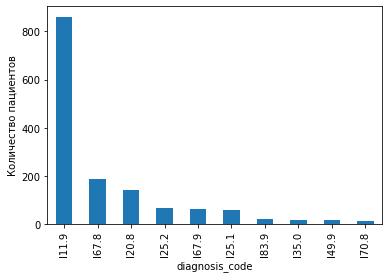

In [ ]:
# слишком много, поэтому визуализируем данные по первым 5 признакам
diagnosis_data[:10].plot(kind = 'bar')
plt.xlabel('diagnosis_code')
plt.ylabel('Количество пациентов')
plt.show()

<h2>Выведем параметры общего и биохимического анализов крови</h2>

<h2>Отфильтруем таблицу по параметрам: диагноз - болезни органов кровоообращения</h2>

In [ ]:
df_cvd = df_all.loc[(df_all['diagnosis_code'].str.contains('I11'))|(df_all['diagnosis_code'].str.contains('I20'))|(df_all['diagnosis_code'].str.contains('I10'))|(df_all['diagnosis_code'].str.contains('I67'))|(df_all['diagnosis_code'].str.contains('I25'))]

In [ ]:
df_cvd

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
7,K_1755633,1958-12-19,ж,2019-01-10 08:31:52,I20.8,6.90,K_548172.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,61.0
8,K_1825607,1988-08-05,м,2019-01-11 14:02:14,I11.9,8.20,K_548954.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,31.0
11,K_2056217,1972-09-28,ж,2019-01-10 09:23:29,I67.8,5.20,K_548235.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,47.0
25,K_1809597,1952-10-15,ж,2019-01-15 10:08:46,I20.8,6.20,K_549997.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,67.0
29,K_2295365,1978-06-23,ж,2019-01-14 11:20:53,I11.9,8.90,K_549474.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,41.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9962,K_1787282,1960-03-09,ж,2019-03-13 10:40:59,I11.9,5.50,K_577603.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,59.0
9966,K_2028819,1988-07-27,ж,2019-03-07 08:17:08,I10,5.14,K_575400.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,31.0
9969,K_984779,1963-11-28,ж,2019-03-06 08:33:50,I67.8,4.68,K_571522.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,56.0
9983,K_1595696,1977-09-26,ж,2019-03-22 16:27:00,I67.8,5.02,K_582856.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,42.0


Выведем список параметров

In [ ]:
df_cvd.ref_test_mnemonic.unique()

array(['WBC', 'MONO', 'RBC'], dtype=object)

<h2>Таблица без болезней органов кровообращения</h2>

In [ ]:
df_not_cvd = df_all.loc[df_all['diagnosis_code'].str.contains('I') == False]

In [ ]:
df_not_cvd

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
0,K_2265317,2015-06-02,ж,2019-01-16 08:43:14,K58.0,5.70,K_550523.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,4.0
1,K_2206442,2010-09-26,м,2019-01-15 15:30:13,K37,10.50,K_550349.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,9.0
2,K_2262258,2014-11-11,м,2019-01-15 08:13:30,J06.9,8.90,K_549882.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,5.0
3,K_1838878,2004-03-26,ж,2019-01-16 16:56:12,G90.9,6.60,K_551109.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,15.0
4,K_1841563,2001-05-10,м,2019-01-11 14:46:50,Z00.3,7.10,K_548989.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,18.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9992,K_1809875,1957-06-05,ж,2019-03-18 15:53:38,K29.3,5.18,K_568176.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,62.0
9993,K_2261197,1971-12-02,ж,2019-03-18 13:04:04,J06.9,4.37,K_579939.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,48.0
9994,K_1770955,1970-04-23,ж,2019-03-19 11:46:47,M42.1,5.40,K_580485.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,49.0
9995,K_1795038,1952-02-01,ж,2019-03-19 11:13:06,H65.9,5.45,K_576555.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,67.0


<h3>Параметры анализа крови</h3>

Если хб один болеет ССЗ, то заболевание есть

In [ ]:
# сортируем по patient_id
# смотрим все строки с patient_id
# если

In [ ]:
# сравним их: если пациент из списка с ССЗ есть в списке без ССЗ, то строку удаляем
for index_1, key_1 in df_not_cvd.iterrows():
    for index_2, key_2 in df_cvd.iterrows():
        if key_1['patient_id'] == key_2['patient_id']:
            print(key_1['patient_id'], key_1['diagnosis_code'])
            df_not_cvd.drop(index_1)

K_1026216 K60.0
K_1026216 K60.0
K_1807322 H66.0
K_1807322 H66.0
K_1807322 H66.0
K_1820478 K80.1
K_1820478 K80.1
K_2288358 J06.8
K_2288358 J06.8
K_2288358 J06.8
K_2288358 J06.8
K_1809400 J41.0
K_1809400 J41.0
K_1809400 J41.0
K_2011030 K29.5
K_2011030 K29.5
K_2011030 K29.5
K_2264694 M42.1
K_2264694 M42.1
K_1087503 J06.8
K_1087503 J06.8
K_1087503 J06.8
K_1806661 N39.0
K_1806661 N39.0
K_1804332 H31.1
K_1804332 H31.1
K_1804332 H31.1
K_1773132 M42.1
K_1773132 M42.1
K_1771625 N40
K_1771625 N40
K_1809783 E06.3
K_1809783 E06.3
K_1770236 E11.7
K_1770236 E11.7
K_1770236 E11.7
K_1756750 J06.9
K_1756750 J06.9
K_2082089 D75.2
K_2082089 D75.2
K_1781960 D47.1
K_1781960 D47.1
K_1781960 D47.1
K_1757139 C61
K_1757139 C61
K_1772875 J20.8
K_1772875 J20.8
K_1781960 D47.1
K_1781960 D47.1
K_1781960 D47.1
K_1783188 E11.7
K_1783188 E11.7
K_1790632 M42.1
K_1790632 M42.1
K_2263094 J06.9
K_2263094 J06.9
K_2263094 J06.9
K_2263094 J06.9
K_1772245 N40
K_1772245 N40
K_1772245 N40
K_1794538 J40
K_1794538 J40
K_1820478 

K_1781960 D47.1
K_1781960 D47.1
K_1781960 D47.1
K_1786065 M42.1
K_1786065 M42.1
K_1772355 N95.1
K_1772355 N95.1
K_1793044 J06.9
K_1793044 J06.9
K_1793044 J06.9
K_1769962 K29.5
K_1769962 K29.5
K_1769962 K29.5
K_1769962 K29.5
K_1769962 K29.5
K_1756743 D64.9
K_1756743 D64.9
K_1793957 J06.9
K_1793957 J06.9
K_1793957 J06.9
K_1758336 M42.1
K_1758336 M42.1
K_1758336 M42.1
K_1813838 E11.7
K_1813838 E11.7
K_2265524 K31.7
K_2265524 K31.7
K_2265524 K31.7
K_1831339 C50.8
K_1831339 C50.8
K_1831339 C50.8
K_1831339 C50.8
K_1831339 C50.8
K_1831339 C50.8
K_1808862 J06.9
K_1808862 J06.9
K_1794212 D27
K_1794212 D27
K_1794212 D27
K_1827768 C92.7
K_1827768 C92.7
K_1817166 R05
K_1817166 R05
K_1817166 R05
K_1772324 J20.8
K_1772324 J20.8
K_2011030 D18.0
K_2011030 D18.0
K_2011030 D18.0
K_1789783 N87.0
K_1789783 N87.0
K_1789783 N87.0
K_1769073 E11.7
K_1769073 E11.7
K_1815537 J42
K_1815537 J42
K_1831339 C50.8
K_1831339 C50.8
K_1831339 C50.8
K_1831339 C50.8
K_1831339 C50.8
K_1831339 C50.8
K_2261203 J02.8
K_226120

In [ ]:
df_cvd

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
7,K_1755633,1958-12-19,ж,2019-01-10 08:31:52,I20.8,6.90,K_548172.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,61.0
8,K_1825607,1988-08-05,м,2019-01-11 14:02:14,I11.9,8.20,K_548954.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,31.0
11,K_2056217,1972-09-28,ж,2019-01-10 09:23:29,I67.8,5.20,K_548235.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,47.0
25,K_1809597,1952-10-15,ж,2019-01-15 10:08:46,I20.8,6.20,K_549997.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,67.0
29,K_2295365,1978-06-23,ж,2019-01-14 11:20:53,I11.9,8.90,K_549474.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,41.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9962,K_1787282,1960-03-09,ж,2019-03-13 10:40:59,I11.9,5.50,K_577603.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,59.0
9966,K_2028819,1988-07-27,ж,2019-03-07 08:17:08,I10,5.14,K_575400.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,31.0
9969,K_984779,1963-11-28,ж,2019-03-06 08:33:50,I67.8,4.68,K_571522.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,56.0
9983,K_1595696,1977-09-26,ж,2019-03-22 16:27:00,I67.8,5.02,K_582856.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,42.0


In [ ]:
df_cvd.ref_test_mnemonic.unique()

array(['WBC', 'MONO', 'RBC'], dtype=object)

In [ ]:
df_not_cvd

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
0,K_2265317,2015-06-02,ж,2019-01-16 08:43:14,K58.0,5.70,K_550523.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,4.0
1,K_2206442,2010-09-26,м,2019-01-15 15:30:13,K37,10.50,K_550349.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,9.0
2,K_2262258,2014-11-11,м,2019-01-15 08:13:30,J06.9,8.90,K_549882.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,5.0
3,K_1838878,2004-03-26,ж,2019-01-16 16:56:12,G90.9,6.60,K_551109.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,15.0
4,K_1841563,2001-05-10,м,2019-01-11 14:46:50,Z00.3,7.10,K_548989.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,18.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9992,K_1809875,1957-06-05,ж,2019-03-18 15:53:38,K29.3,5.18,K_568176.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,62.0
9993,K_2261197,1971-12-02,ж,2019-03-18 13:04:04,J06.9,4.37,K_579939.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,48.0
9994,K_1770955,1970-04-23,ж,2019-03-19 11:46:47,M42.1,5.40,K_580485.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,49.0
9995,K_1795038,1952-02-01,ж,2019-03-19 11:13:06,H65.9,5.45,K_576555.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,67.0


In [ ]:
df_not_cvd.ref_test_mnemonic.unique()

array(['WBC', 'MONO', 'RBC'], dtype=object)

#### <h2>Описательные статистики</h2>

<h3>1.1. sex (с 5 группами ССЗ)</h3>

In [ ]:
# выведем доли мужчин и женщин
sex_cvd_data = (df_cvd['sex'].value_counts())/len(df_cvd['sex'])*100
sex_cvd_data

ж    62.633452
м    37.366548
Name: sex, dtype: float64

Визуализируем это

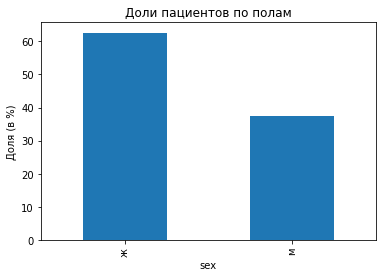

In [ ]:
# визуализируем данные
sex_cvd_data.plot(kind = 'bar')
plt.xlabel('sex')
plt.ylabel('Доля (в %)')
plt.title('Доли пациентов по полам')
plt.show()

<h3>1.2. sex (без ССЗ)</h3>

In [ ]:
# выведем доли мужчин и женщин
sex_not_cvd_data = (df_not_cvd['sex'].value_counts())/len(df_not_cvd['sex'])*100
sex_not_cvd_data

ж    66.372946
м    33.627054
Name: sex, dtype: float64

Визуализируем это

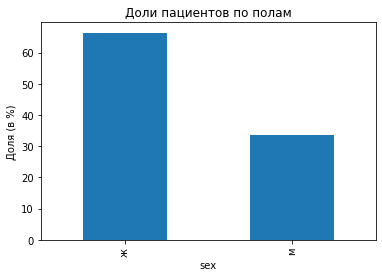

In [ ]:
# визуализируем данные
sex_not_cvd_data.plot(kind = 'bar')
plt.xlabel('sex')
plt.ylabel('Доля (в %)')
plt.title('Доли пациентов по полам')
plt.show()

<h3>2.1. age_when_sampling (с 5 самыми распространенными заболеваниями ССЗ)</h3>

<h4>Среднее арифметическое и стандартное отклонение</h4>

In [ ]:
age_cvd_mean = df_cvd['age_when_sampling'].mean()     # среднее
age_cvd_std = df_cvd['age_when_sampling'].std()     # стандатрное отклонение
print("Среднее значение возраста: \n", age_cvd_mean , '±', age_cvd_std, 'лет')

Среднее значение возраста: 
 60.677580071174376 ± 12.559401416482524 лет


<h4>Проверим выборку на нормальность</h4>

<u>Гипотеза H0: возраст пациентов с ССЗ имеет распределение, не отличающееся от нормального.</u><br>
<u>Гипотеза Ha: возраст пациентов с ССЗ имеет распределение, отличающееся от нормального.</u>

In [ ]:
from scipy.stats import shapiro
stat, p_age = shapiro(df_cvd['age_when_sampling'])
print('Вероятность по критерию Шапиро-Уилка', p_age)
if (p_age < 0.05):
    print("Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена")
else:
    print("Нет оснований отклонить гипотезу о нормальном распределении возраста пациентов с ССЗ")

Вероятность по критерию Шапиро-Уилка 1.0267708461242364e-08
Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена


<h3>2.2. age_when_sampling (без ССЗ)</h3>

<h4>Среднее арифметическое и стандартное отклонение</h4>

In [ ]:
age_not_cvd_mean = df_not_cvd['age_when_sampling'].mean()     # среднее
age_not_cvd_std = df_not_cvd['age_when_sampling'].std()     # стандатрное отклонение
print("Среднее значение возраста: \n", age_not_cvd_mean , '±', age_not_cvd_std, 'лет')

Среднее значение возраста: 
 39.304000952607765 ± 22.298944600155757 лет


<h4>Проверим выборку на нормальность</h4>

In [ ]:
from scipy.stats import shapiro
stat, p_age = shapiro(df_not_cvd['age_when_sampling'])
print('Вероятность по критерию Шапиро-Уилка', p_age)
if (p_age < 0.05):
    print("Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена")
else:
    print("Нет оснований отклонить гипотезу о нормальном распределении возраста пациентов с ССЗ")

Вероятность по критерию Шапиро-Уилка 4.028733084933849e-42
Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена


C:\Users\olgap\anaconda3\lib\site-packages\scipy\stats\morestats.py:1760: UserWarning: p-value may not be accurate for N > 5000.
  warnings.warn("p-value may not be accurate for N > 5000.")


<u>Гипотеза H0: возраст пациентов без ССЗ имеет распределение, не отличающееся от нормального.</u><br>
<u>Гипотеза Ha: возраст пациентов без ССЗ имеет распределение, отличающееся от нормального.</u>

Проверяем с помощью критерия Манна-Уитни

In [ ]:
import scipy.stats
m_wh = scipy.stats.mannwhitneyu(df_cvd['age_when_sampling'], df_not_cvd['age_when_sampling'])
if m_wh.pvalue < 0.05:
    print('Между средними арифметическими выборок наблюдается статистически достоверная разница')
else:
    print('Между средними арифметическими выборок статистически достоверная разница НЕ наблюдается')

Между средними арифметическими выборок наблюдается статистически достоверная разница


Таким образом, возраст является одним из признаков, по которому можно сделать дерево решений

In [ ]:
age_not_cvd_normalized

[-1.5832139854888545,
 -1.3589881268370025,
 -1.538368813758484,
 -1.0899170964547804,
 -0.9553815812636692,
 -1.1347622681851508,
 1.1971866617941087,
 -0.41723952049922475,
 1.7801738942889234,
 1.0626511466029975,
 -1.3589881268370025,
 -1.628059157219225,
 0.8384252879511457,
 0.03121219680447895,
 0.16574771199559007,
 1.242031833524479,
 1.5111028639067012,
 0.524509085838553,
 0.7038897727600345,
 -1.3141429551066321,
 -1.3141429551066321,
 -0.9553815812636692,
 0.883270459681516,
 0.1209025402652197,
 1.1523414900637383,
 -0.8208460660725582,
 -1.7177495006799655,
 1.4662576921763308,
 1.600793207367442,
 0.03121219680447895,
 0.3002832271867012,
 -0.10332331838663217,
 -1.7177495006799655,
 -1.628059157219225,
 -1.3589881268370025,
 -0.9553815812636692,
 0.1209025402652197,
 0.9729608031422567,
 0.8384252879511457,
 0.7487349444904049,
 1.0178059748726271,
 0.47966391410818265,
 1.0626511466029975,
 1.242031833524479,
 0.9729608031422567,
 1.600793207367442,
 -0.14816849011700

<h3>3.1. district_name (с 5 самыми распространенными заболеваниями ССЗ)</h3>

<h3>2.4.Нормализация значений признака age_when_sampling</h3>

In [ ]:
# выведем количество пациентов в Ишимском районе и пациентов в Кондинском районе
district_data = (df_cvd['district_name'].value_counts())/len(df_cvd['district_name'])*100
district_data

Кондинский район    100.0
Name: district_name, dtype: float64

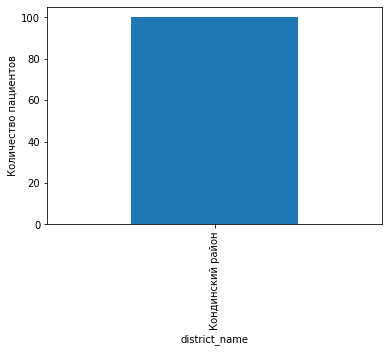

In [ ]:
# визуализируем данные
district_data.plot(kind = 'bar')
plt.xlabel('district_name')
plt.ylabel('Количество пациентов')
plt.show()

<h3>3.2. district_name (без ССЗ)</h3>

In [ ]:
# выведем количество пациентов в Ишимском районе и пациентов в Кондинском районе
district_data = (df_not_cvd['district_name'].value_counts())/len(df_not_cvd['district_name'])*100
district_data

Кондинский район    100.0
Name: district_name, dtype: float64

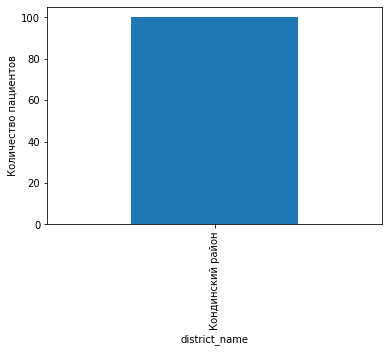

In [ ]:
# визуализируем данные
district_data.plot(kind = 'bar')
plt.xlabel('district_name')
plt.ylabel('Количество пациентов')
plt.show()

Район, возможно, также можно отнести к признакам, по которому можно классифицировать ССЗ.

<h3>Исследуем параметры анализов крови</h3>

ССЗ: 'WBC', 'MONO', 'RBC'

Не-ССЗ: 'WBC', 'MONO', 'RBC'

<h3>4.1. WBC (с 5 самыми распространенными заболеваниями ССЗ)</h3>

In [ ]:
df_cvd_wbc = df_cvd.loc[(df_cvd['ref_test_mnemonic'] == 'WBC')]

In [ ]:
df_cvd_wbc

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
7,K_1755633,1958-12-19,ж,2019-01-10 08:31:52,I20.8,6.9,K_548172.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,61.0
8,K_1825607,1988-08-05,м,2019-01-11 14:02:14,I11.9,8.2,K_548954.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,31.0
11,K_2056217,1972-09-28,ж,2019-01-10 09:23:29,I67.8,5.2,K_548235.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,47.0
25,K_1809597,1952-10-15,ж,2019-01-15 10:08:46,I20.8,6.2,K_549997.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,67.0
29,K_2295365,1978-06-23,ж,2019-01-14 11:20:53,I11.9,8.9,K_549474.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,41.0
...,...,...,...,...,...,...,...,...,...,...,...,...
3851,K_1813838,1950-11-17,ж,2019-05-08 14:31:37,I11.9,9.4,K_602271.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,69.0
3852,K_1915873,1969-09-04,ж,2019-05-07 08:25:47,I25.2,4.6,K_601698.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,50.0
3854,K_1769962,1951-01-24,ж,2019-05-08 08:19:54,I11.9,5.0,K_602028.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,68.0
3855,K_1995075,1962-05-24,ж,2019-05-06 17:13:05,I11.9,6.5,K_601660.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,57.0


<h4>Среднее арифметическое и стандартное отклонение</h4>

In [ ]:
wbc_cvd_mean = df_cvd_wbc['result'].mean()     # среднее
wbc_cvd_std = df_cvd_wbc['result'].std()     # стандатрное отклонение
print("Среднее значение признака WBC (количество лейкоцитов) у пациентов с 5 самыми распространенными ССЗ: \n", wbc_cvd_mean , '±', wbc_cvd_std, '* 10^9/л')

Среднее значение признака WBC (количество лейкоцитов) у пациентов с 5 самыми распространенными ССЗ: 
 7.558469945355196 ± 2.025121927821625 * 10^9/л


<h4>Проверим выборку на нормальность</h4>

<u>Гипотеза H0: значение признака WBC с 5 самыми распространенными ССЗ имеет распределение, не отличающееся от нормального.</u><br>
<u>Гипотеза Ha: значение признака WBC с 5 самыми распространенными ССЗ имеет распределение, отличающееся от нормального.</u>

In [ ]:
from scipy.stats import shapiro
stat_wbc_cvd, p_wbc_cvd = shapiro(df_cvd_wbc['result'])
print('Вероятность по критерию Шапиро-Уилка', p_wbc_cvd)
if (p_wbc_cvd < 0.05):
    print("Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена")
else:
    print("Нет оснований отклонить гипотезу о нормальном распределении возраста пациентов с ССЗ")

Вероятность по критерию Шапиро-Уилка 6.811131519901537e-11
Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена


<h3>4.2. WBC (без ССЗ) </h3>

In [ ]:
df_not_cvd_wbc = df_not_cvd.loc[(df_not_cvd['ref_test_mnemonic'] == 'WBC')]

In [ ]:
df_not_cvd_wbc

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
0,K_2265317,2015-06-02,ж,2019-01-16 08:43:14,K58.0,5.7,K_550523.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,4.0
1,K_2206442,2010-09-26,м,2019-01-15 15:30:13,K37,10.5,K_550349.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,9.0
2,K_2262258,2014-11-11,м,2019-01-15 08:13:30,J06.9,8.9,K_549882.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,5.0
3,K_1838878,2004-03-26,ж,2019-01-16 16:56:12,G90.9,6.6,K_551109.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,15.0
4,K_1841563,2001-05-10,м,2019-01-11 14:46:50,Z00.3,7.1,K_548989.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,18.0
...,...,...,...,...,...,...,...,...,...,...,...,...
3867,K_1811369,1960-10-20,ж,2019-06-13 09:17:41,L29.8,5.6,K_617685.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,59.0
3868,K_2263656,2012-10-16,ж,2019-06-17 13:38:14,J20.9,9.2,K_618807.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,7.0
3869,K_2265939,1971-12-25,ж,2019-06-17 14:53:53,T93.8,6.6,K_611359.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,48.0
3870,K_1841908,1960-05-17,ж,2019-06-24 09:27:08,L04.0,7.5,K_621850.0,Общий анализ крови,Лейкоциты,WBC,Кондинский район,59.0


<h4>Среднее арифметическое и стандартное отклонение</h4>

In [ ]:
wbc_not_cvd_mean = df_not_cvd_wbc['result'].mean()     # среднее
wbc_not_cvd_std = df_not_cvd_wbc['result'].std()     # стандатрное отклонение
print("Среднее значение признака WBC (количество лейкоцитов) у пациентов без ССЗ: \n", wbc_not_cvd_mean , '±', wbc_not_cvd_std, '* 10^9/л')

Среднее значение признака WBC (количество лейкоцитов) у пациентов без ССЗ: 
 7.608990147783254 ± 2.7438324313557585 * 10^9/л


<h4>Проверим выборку на нормальность</h4>

<u>Гипотеза H0: значение признака WBC без ССЗ имеет распределение, не отличающееся от нормального.</u><br>
<u>Гипотеза Ha: значение признака WBC без ССЗ имеет распределение, отличающееся от нормального.</u>

In [ ]:
from scipy.stats import shapiro
stat_not_wbc_cvd, p_wbc_not_cvd = shapiro(df_not_cvd_wbc['result'])
print('Вероятность по критерию Шапиро-Уилка', p_wbc_not_cvd)
if (p_wbc_not_cvd < 0.05):
    print("Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена")
else:
    print("Нет оснований отклонить гипотезу о нормальном распределении возраста пациентов с ССЗ")

Вероятность по критерию Шапиро-Уилка 0.0
Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена


<h3>4.3. Сравнение WBC (с ССЗ) и WBC (без ССЗ)</h3>

Проверяем с помощью критерия Манна-Уитни

In [ ]:
import scipy.stats
m_wh = scipy.stats.mannwhitneyu(df_cvd_wbc['result'], df_not_cvd_wbc['result'])
if m_wh.pvalue < 0.05:
    print('Между средними арифметическими выборок наблюдается статистически достоверная разница')
else:
    print('Между средними арифметическими выборок статистически достоверная разница НЕ наблюдается')

Между средними арифметическими выборок статистически достоверная разница НЕ наблюдается


Таким образом, WBC к признакам для дерева решений не относим

<h3>5.1. MONO (с 5 самыми распространенными заболеваниями ССЗ)</h3>

In [ ]:
df_cvd_mono = df_cvd.loc[(df_cvd['ref_test_mnemonic'] == 'MONO')]

In [ ]:
df_cvd_mono

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
3877,K_1790622,1943-08-09,ж,2019-01-17 12:45:48,I11.9,7.4,K_544574.0,Общий анализ крови,Моноциты,MONO,Кондинский район,76.0
3884,K_1755633,1958-12-19,ж,2019-01-10 08:31:52,I20.8,9.2,K_548172.0,Общий анализ крови,Моноциты,MONO,Кондинский район,61.0
3895,K_1755573,1957-12-05,м,2019-01-16 16:33:31,I20.8,11.0,K_551089.0,Общий анализ крови,Моноциты,MONO,Кондинский район,62.0
3906,K_1770075,1963-08-28,ж,2019-01-14 10:00:00,I20.8,10.1,K_549326.0,Общий анализ крови,Моноциты,MONO,Кондинский район,56.0
3907,K_1790227,1977-02-02,м,2019-01-17 15:32:54,I11.9,12.9,K_551737.0,Общий анализ крови,Моноциты,MONO,Кондинский район,42.0
...,...,...,...,...,...,...,...,...,...,...,...,...
7698,K_1770357,1959-07-01,м,2019-05-06 13:09:36,I20.8,7.5,K_601424.0,Общий анализ крови,Моноциты,MONO,Кондинский район,60.0
7703,K_1794538,1942-01-28,м,2019-05-07 13:51:24,I25.0,8.6,K_601917.0,Общий анализ крови,Моноциты,MONO,Кондинский район,77.0
7711,K_1787540,1959-08-30,ж,2019-04-30 09:52:23,I11.9,11.0,K_600030.0,Общий анализ крови,Моноциты,MONO,Кондинский район,60.0
7712,K_1772590,1953-01-05,ж,2019-05-06 15:49:29,I11.9,14.5,K_601613.0,Общий анализ крови,Моноциты,MONO,Кондинский район,66.0


<h4>Среднее арифметическое и стандартное отклонение</h4>

In [ ]:
mono_cvd_mean = df_cvd_mono['result'].mean()     # среднее
mono_cvd_std = df_cvd_mono['result'].std()     # стандатрное отклонение
print("Среднее значение признака MONO: \n", mono_cvd_mean , '±', mono_cvd_std, '%')

Среднее значение признака MONO: 
 9.810786106032905 ± 2.1232389220480217 %


<h4>Проверим выборку на нормальность</h4>

<u>Гипотеза H0: значение признака MONO с 5 самыми распространенными ССЗ имеет распределение, не отличающееся от нормального.</u><br>
<u>Гипотеза Ha: значение признака MONO с 5 самыми распространенными ССЗ имеет распределение, отличающееся от нормального.</u>

In [ ]:
from scipy.stats import shapiro
stat_mono_cvd, p_mono_cvd = shapiro(df_cvd_mono['result'])
print('Вероятность по критерию Шапиро-Уилка', p_mono_cvd)
if (p_mono_cvd < 0.05):
    print("Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена")
else:
    print("Нет оснований отклонить гипотезу о нормальном распределении возраста пациентов с ССЗ")

Вероятность по критерию Шапиро-Уилка 1.5871356708885287e-06
Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена


<h3>5.2. MONO (без ССЗ) </h3>

In [ ]:
df_not_cvd_mono = df_not_cvd.loc[(df_not_cvd['ref_test_mnemonic'] == 'MONO')]

In [ ]:
df_not_cvd_mono

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
3872,K_2265317,2015-06-02,ж,2019-01-16 08:43:14,K58.0,11.7,K_550523.0,Общий анализ крови,Моноциты,MONO,Кондинский район,4.0
3873,K_1798125,1974-11-16,м,2019-01-21 09:43:41,J06.8,8.5,K_552766.0,Общий анализ крови,Моноциты,MONO,Кондинский район,45.0
3874,K_2295883,2016-02-25,ж,2019-01-14 16:48:11,J06.9,12.2,K_548876.0,Общий анализ крови,Моноциты,MONO,Кондинский район,3.0
3875,K_2261810,2014-01-15,м,2019-01-14 11:35:58,J06.9,9.7,K_548165.0,Общий анализ крови,Моноциты,MONO,Кондинский район,5.0
3876,K_2263716,1987-06-21,ж,2019-01-17 12:36:09,M42.1,10.7,K_551518.0,Общий анализ крови,Моноциты,MONO,Кондинский район,32.0
...,...,...,...,...,...,...,...,...,...,...,...,...
7726,K_1810706,1961-07-28,м,2019-06-17 13:08:29,E11.7,2.6,K_619105.0,Общий анализ крови,Моноциты,MONO,Кондинский район,58.0
7727,K_1841908,1960-05-17,ж,2019-06-24 09:27:08,L04.0,8.0,K_621850.0,Общий анализ крови,Моноциты,MONO,Кондинский район,59.0
7728,K_2302899,2018-01-05,ж,2019-06-18 13:10:54,Z00.0,8.5,K_619741.0,Общий анализ крови,Моноциты,MONO,Кондинский район,1.0
7729,K_2263656,2012-10-16,ж,2019-06-17 08:35:17,J20.9,9.1,K_618807.0,Общий анализ крови,Моноциты,MONO,Кондинский район,7.0


<h4>Среднее арифметическое и стандартное отклонение</h4>

In [ ]:
mono_not_cvd_mean = df_not_cvd_mono['result'].mean()     # среднее
mono_not_cvd_std = df_not_cvd_mono['result'].std()     # стандатрное отклонение
print("Среднее значение признака MONO: \n", mono_not_cvd_mean , '±', mono_not_cvd_std, '%')

Среднее значение признака MONO: 
 9.838955823293174 ± 2.9891293401592893 %


<h4>Проверим выборку на нормальность</h4>

<u>Гипотеза H0: значение признака MONO без ССЗ имеет распределение, не отличающееся от нормального.</u><br>
<u>Гипотеза Ha: значение признака MONO без ССЗ имеет распределение, отличающееся от нормального.</u>

In [ ]:
from scipy.stats import shapiro
stat_mono_not_cvd, p_mono_not_cvd = shapiro(df_not_cvd_mono['result'])
print('Вероятность по критерию Шапиро-Уилка', p_mono_not_cvd)
if (p_mono_not_cvd < 0.05):
    print("Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена")
else:
    print("Нет оснований отклонить гипотезу о нормальном распределении возраста пациентов с ССЗ")

Вероятность по критерию Шапиро-Уилка 0.0
Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена


Проверяем по критерию Манна-Уитни

In [ ]:
import scipy.stats
m_wh = scipy.stats.mannwhitneyu(df_cvd_mono['result'], df_not_cvd_mono['result'])
if m_wh.pvalue < 0.05:
    print('Между средними арифметическими выборок наблюдается статистически достоверная разница')
else:
    print('Между средними арифметическими выборок статистически достоверная разница НЕ наблюдается')

Между средними арифметическими выборок статистически достоверная разница НЕ наблюдается


Таким образом, MONO к признакам для дерева решений не относим

<h3>6.1. RBC (с 5 самыми распространенными заболеваниями ССЗ)</h3>

Таблица значений признака RBC (количества эритроцитов) по пациентам с 5 самыми распространенными заболеваниями ССЗ

In [ ]:
df_cvd_rbc = df_cvd.loc[(df_cvd['ref_test_mnemonic'] == 'RBC')]

In [ ]:
df_cvd_rbc

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
7736,K_1814533,1940-11-15,ж,2019-01-17 13:44:56,I11.9,2.62,K_547233.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,79.0
7741,K_1793530,1967-09-14,ж,2019-01-14 11:05:43,I67.9,4.64,K_549454.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,52.0
7746,K_1792987,1954-10-03,м,2019-01-15 10:36:08,I25.2,5.70,K_550030.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,65.0
7751,K_1756705,1946-12-06,ж,2019-01-21 16:47:35,I11.9,4.01,K_553220.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,73.0
7759,K_1770075,1963-08-28,ж,2019-01-14 10:00:00,I20.8,4.31,K_549326.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,56.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9962,K_1787282,1960-03-09,ж,2019-03-13 10:40:59,I11.9,5.50,K_577603.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,59.0
9966,K_2028819,1988-07-27,ж,2019-03-07 08:17:08,I10,5.14,K_575400.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,31.0
9969,K_984779,1963-11-28,ж,2019-03-06 08:33:50,I67.8,4.68,K_571522.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,56.0
9983,K_1595696,1977-09-26,ж,2019-03-22 16:27:00,I67.8,5.02,K_582856.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,42.0


<h4>Среднее арифметическое и стандартное отклонение</h4>

In [ ]:
rbc_cvd_mean = df_cvd_rbc['result'].mean()     # среднее
rbc_cvd_std = df_cvd_rbc['result'].std()     # стандатрное отклонение
print("Среднее значение признака RBC (количество эритроцитов) у пациентов с 5 самыми распространенными ССЗ: \n", rbc_cvd_mean , '±', rbc_cvd_std, '* 10^12/л')

Среднее значение признака RBC (количество эритроцитов) у пациентов с 5 самыми распространенными ССЗ: 
 4.870097087378641 ± 0.6118051242217222 * 10^12/л


<h4>Проверим выборку на нормальность</h4>

<u>Гипотеза H0: значение признака RBC с 5 самыми распространенными ССЗ имеет распределение, не отличающееся от нормального.</u><br>
<u>Гипотеза Ha: значение признака RBC с 5 самыми распространенными ССЗ имеет распределение, отличающееся от нормального.</u>

In [ ]:
from scipy.stats import shapiro
stat_rbc_cvd, p_rbc_cvd = shapiro(df_cvd_rbc['result'])
print('Вероятность по критерию Шапиро-Уилка', p_rbc_cvd)
if (p_rbc_cvd < 0.05):
    print("Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена")
else:
    print("Нет оснований отклонить гипотезу о нормальном распределении возраста пациентов с ССЗ")

Вероятность по критерию Шапиро-Уилка 1.509251751352636e-10
Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена


<h3>6.2. RBC (без ССЗ)</h3>

In [ ]:
df_not_cvd_rbc = df_not_cvd.loc[(df_not_cvd['ref_test_mnemonic'] == 'RBC')]

In [ ]:
df_not_cvd_rbc

,patient_id,birthday,sex,sampling_date,diagnosis_code,result,referral_id,ref_analysis_name,ref_test_name,ref_test_mnemonic,district_name,age_when_sampling
7731,K_2265317,2015-06-02,ж,2019-01-16 08:43:14,K58.0,4.69,K_550523.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,4.0
7732,K_1087517,1962-02-14,ж,2019-01-10 10:30:01,K80.1,4.75,K_548308.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,57.0
7733,K_1808274,1949-11-13,м,2019-01-10 12:59:05,D64.9,1.46,K_548444.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,70.0
7734,K_1833910,1978-11-16,ж,2019-01-22 08:06:23,J06.9,5.15,K_553295.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,41.0
7735,K_2302501,2017-11-08,ж,2019-01-14 16:46:56,J06.9,4.76,K_548874.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9992,K_1809875,1957-06-05,ж,2019-03-18 15:53:38,K29.3,5.18,K_568176.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,62.0
9993,K_2261197,1971-12-02,ж,2019-03-18 13:04:04,J06.9,4.37,K_579939.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,48.0
9994,K_1770955,1970-04-23,ж,2019-03-19 11:46:47,M42.1,5.40,K_580485.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,49.0
9995,K_1795038,1952-02-01,ж,2019-03-19 11:13:06,H65.9,5.45,K_576555.0,Общий анализ крови,Эритроциты,RBC,Кондинский район,67.0


<h4>Среднее арифметическое и стандартное отклонение</h4>

In [ ]:
rbc_not_cvd_mean = df_not_cvd_rbc['result'].mean()     # среднее
rbc_not_cvd_std = df_not_cvd_rbc['result'].std()     # стандатрное отклонение
print("Среднее значение признака RBC (количество эритроцитов) у пациентов без ССЗ: \n", rbc_not_cvd_mean , '±', rbc_not_cvd_std, '* 10^12/л')

Среднее значение признака RBC (количество эритроцитов) у пациентов без ССЗ: 
 4.997903815995815 ± 8.729377577726238 * 10^12/л


Надо сжать выборку (убрать до 3 сигма и после 3 сигма)

In [ ]:
df_not_cvd_rbc = df_not_cvd_rbc[df_not_cvd_rbc['result'] <= df_not_cvd_rbc['result'].mean()+2.8*df_not_cvd_rbc['result'].std()]
df_not_cvd_rbc = df_not_cvd_rbc[df_not_cvd_rbc['result'] >= df_not_cvd_rbc['result'].mean()-2.8*df_not_cvd_rbc['result'].std()]


Делаем среднее и сигму снова

In [ ]:
rbc_not_cvd_mean = df_not_cvd_rbc['result'].mean()     # среднее
rbc_not_cvd_std = df_not_cvd_rbc['result'].std()     # стандатрное отклонение
print("Среднее значение признака RBC (количество эритроцитов) у пациентов без ССЗ: \n", rbc_not_cvd_mean , '±', rbc_not_cvd_std, '* 10^12/л')

Среднее значение признака RBC (количество эритроцитов) у пациентов без ССЗ: 
 4.815021119324179 ± 0.46054570926208693 * 10^12/л


<h4>Проверим выборку на нормальность</h4>

<u>Гипотеза H0: значение признака RBC без ССЗ имеет распределение, не отличающееся от нормального.</u><br>
<u>Гипотеза Ha: значение признака RBC без ССЗ имеет распределение, отличающееся от нормального.</u>

In [ ]:
from scipy.stats import shapiro
stat_rbc_not_cvd, p_rbc_not_cvd = shapiro(df_not_cvd_rbc['result'])
print('Вероятность по критерию Шапиро-Уилка', p_rbc_not_cvd)
if (p_rbc_not_cvd < 0.05):
    print("Гипотеза о нормальном распределении возраста пациентов с ССЗ отклонена")
else:
    print("Нет оснований отклонить гипотезу о нормальном распределении возраста пациентов с ССЗ")

Вероятность по критерию Шапиро-Уилка 0.6399887800216675
Нет оснований отклонить гипотезу о нормальном распределении возраста пациентов с ССЗ


Проверяем по критерию Манна-Уитни

In [ ]:
import scipy.stats
m_wh = scipy.stats.mannwhitneyu(df_cvd_rbc['result'], df_not_cvd_rbc['result'])
if m_wh.pvalue < 0.05:
    print('Между средними арифметическими выборок наблюдается статистически достоверная разница')
else:
    print('Между средними арифметическими выборок статистически достоверная разница НЕ наблюдается')

Между средними арифметическими выборок наблюдается статистически достоверная разница


Таким образом, признак 'RBC' (количество эритроцитов) является одним из признаков, по которому можно сделать дерево решений. Можно нормализовать

<h3>6.4.Нормализация значений признака RBC</h3>

<h3>6.4.1. Нормализация значений признака RBC у пациентов с 5 самыми распространенными ССЗ в выборке</h3>

In [ ]:
# сделаем список
rbc_cvd_normalized = []
# добавим значения в список
for el in df_cvd_rbc['result']:
    rbc_cvd_normalized.append((el-df_cvd_rbc['result'].mean())/df_cvd_rbc['result'].std())

In [ ]:
rbc_cvd_normalized

[-3.677800329379377,
 -0.37609539094878897,
 1.3564824480296398,
 -1.4058350499642696,
 -0.9154828313854694,
 1.1766866345507456,
 0.8170950075929593,
 -0.19629957746989496,
 -0.1309192816593882,
 -0.5558912044276815,
 0.3103977150615314,
 -4.2008426958634315,
 1.0786161908349863,
 0.6372991941140652,
 -0.0491939118962551,
 0.21232727134577198,
 0.3267427890141592,
 -0.8991377574328416,
 -1.4548702718221491,
 0.9642006731665991,
 0.032531457866878,
 -0.8991377574328416,
 0.5555738243509322,
 0.16329204948789153,
 -0.686651796048695,
 -0.01650376399100099,
 -0.6539616481434424,
 0.1469469755352652,
 -0.1636094295646423,
 -0.09822913375413554,
 0.04887653181950578,
 -0.8010673137170822,
 -1.4548702718221491,
 0.9805457471192254,
 -0.9808631271959762,
 -0.686651796048695,
 -0.1309192816593882,
 -0.03284883794362877,
 -0.2453347993277754,
 0.4248132327299186,
 0.7680597857350788,
 -0.5395461304750552,
 -1.0462434230064814,
 -0.0491939118962551,
 0.11425682763001255,
 0.27770756715627876,
 

<h3>6.4.2. Нормализация значений признака RBC без ССЗ</h3>

In [ ]:
# сделаем список
rbc_not_cvd_normalized = []
# добавим значения в список
for el in df_not_cvd_rbc['result']:
    rbc_not_cvd_normalized.append((el-df_not_cvd_rbc['result'].mean())/df_not_cvd_rbc['result'].std())

In [ ]:
rbc_not_cvd_normalized

[-0.27146299880742447,
 -0.14118277082281228,
 0.7273520824079421,
 -0.11946939949204391,
 0.5319317404310209,
 2.0952944762463788,
 -0.5971635687689578,
 0.8793456817233227,
 1.2267596230156244,
 0.8142055677310175,
 0.5102183691002525,
 -0.6188769400997263,
 0.6839253397464035,
 -0.05432928549973685,
 -0.31488974146896315,
 -0.07604265683050522,
 0.1410910564771824,
 -1.6176920213150927,
 -1.0748577380458717,
 0.1410910564771824,
 -0.20632288481511935,
 0.7707788250694788,
 -0.7057304254228016,
 -0.7708705394151087,
 0.032524199823338595,
 -0.6188769400997263,
 0.22794454180025786,
 -0.4668833407843457,
 -0.488596712115114,
 -1.574265278653556,
 -1.6394053926458632,
 -0.6188769400997263,
 1.0530526523694737,
 0.662211968415635,
 -1.5308385359920174,
 -1.5308385359920174,
 -0.9880042527227964,
 -0.2497496274766561,
 0.5102183691002525,
 0.8142055677310175,
 -0.05432928549973685,
 0.4667916264387158,
 -1.2485647086920226,
 0.662211968415635,
 -0.7491571680843404,
 0.5319317404310209,
 

<h3>6.5. Нормализация значений age_when_sampling (с ССЗ)</h3>

In [ ]:
# сделаем список
age_cvd_normalized = []
# добавим значения в список
for el in df_cvd_rbc['age_when_sampling']:
    age_cvd_normalized.append((el-df_cvd_rbc['age_when_sampling'].mean())/df_cvd_rbc['age_when_sampling'].std())

In [ ]:
age_cvd_normalized

[1.4382659727590368,
 -0.7010552985422016,
 0.328988276528765,
 0.9628612458032061,
 -0.3841188139049811,
 0.40822239768807017,
 0.09128591305084964,
 -0.7802894197015068,
 -0.0671823292677606,
 1.0420953669625113,
 -0.22565057158637086,
 1.4382659727590368,
 0.8836271246439009,
 -2.68190832752483,
 0.7251588823252907,
 0.7251588823252907,
 -0.46335293506428626,
 0.6459247611659855,
 0.328988276528765,
 0.24975415536945988,
 -0.14641645042706575,
 1.2005636092811214,
 0.012051791891544518,
 0.24975415536945988,
 1.1213294881218163,
 0.8836271246439009,
 0.09128591305084964,
 -1.6518647524538632,
 -0.5425870562235914,
 0.24975415536945988,
 -1.4933965101352529,
 -2.4442059640469145,
 -0.938757662020117,
 0.012051791891544518,
 0.24975415536945988,
 1.7552024573962572,
 0.5666906400066805,
 -1.8895671159317786,
 -0.0671823292677606,
 -0.46335293506428626,
 0.012051791891544518,
 0.09128591305084964,
 1.5175000939183418,
 0.012051791891544518,
 -0.7010552985422016,
 1.8344365785555625,
 -

<h3>6.5.2. Нормализация значений age_when_sampling (без ССЗ)</h3>

In [ ]:
# сделаем список

age_not_cvd_normalized = []

# добавим значения в список

for el in df_not_cvd_rbc['age_when_sampling']:

    age_not_cvd_normalized.append((el-df_not_cvd_rbc['age_when_sampling'].mean())/df_not_cvd_rbc['age_when_sampling'].std())

In [ ]:
age_not_cvd_normalized

[-1.522776344866192,
 0.8263397752235265,
 0.11717264463040397,
 -1.6114222361903323,
 -1.6114222361903323,
 -0.9022551055972098,
 -1.5670992905282621,
 0.3387873729407548,
 -1.4784533992041218,
 -1.6557451818524025,
 1.0479545035338773,
 1.5798298514787192,
 1.1366003948580177,
 -1.0795468882454904,
 -1.522776344866192,
 0.2058185359545443,
 0.2501414816166145,
 -0.9909009969213501,
 0.5160791555890354,
 1.491183960154579,
 0.2501414816166145,
 -0.9909009969213501,
 -0.3260568119902976,
 -0.9022551055972098,
 0.8263397752235265,
 0.16149559029247415,
 1.3582151231683686,
 -0.5033485946385783,
 1.0036315578718071,
 1.0036315578718071,
 -0.2817338663282275,
 0.11717264463040397,
 1.1809233405200878,
 -1.3898075078799816,
 -0.9022551055972098,
 1.1366003948580177,
 0.07284969896833382,
 1.1366003948580177,
 1.0036315578718071,
 1.0036315578718071,
 -1.256838670893771,
 -1.4784533992041218,
 1.0036315578718071,
 -0.060119138017876675,
 1.6241527971407894,
 -1.6114222361903323,
 -1.6114222

<h2>7. ДЕРЕВО РЕШЕНИЙ</h2>

Пусть в исходных признаках (X) будут ‘age_when_sampling’, ’‘result’,
а целевым признаком (Y) будет 'diagnosis_code'

In [ ]:
# сделаем массивы для обучения и тестирования
# перемешаем выборку X
import random
X = np.array([age_cvd_normalized + age_not_cvd_normalized, rbc_cvd_normalized + rbc_not_cvd_normalized])
y = np.array(pd.concat([df_cvd_rbc['diagnosis_code'], df_not_cvd_rbc['diagnosis_code']]))

In [ ]:
X_new = []
for i in range(min(len(age_cvd_normalized + age_not_cvd_normalized), len(rbc_cvd_normalized + rbc_not_cvd_normalized))):
    X_new.append([X[0][i], X[1][i]])

In [ ]:
X_new

[[1.4382659727590368, -3.677800329379377],
 [-0.7010552985422016, -0.37609539094878897],
 [0.328988276528765, 1.3564824480296398],
 [0.9628612458032061, -1.4058350499642696],
 [-0.3841188139049811, -0.9154828313854694],
 [0.40822239768807017, 1.1766866345507456],
 [0.09128591305084964, 0.8170950075929593],
 [-0.7802894197015068, -0.19629957746989496],
 [-0.0671823292677606, -0.1309192816593882],
 [1.0420953669625113, -0.5558912044276815],
 [-0.22565057158637086, 0.3103977150615314],
 [1.4382659727590368, -4.2008426958634315],
 [0.8836271246439009, 1.0786161908349863],
 [-2.68190832752483, 0.6372991941140652],
 [0.7251588823252907, -0.0491939118962551],
 [0.7251588823252907, 0.21232727134577198],
 [-0.46335293506428626, 0.3267427890141592],
 [0.6459247611659855, -0.8991377574328416],
 [0.328988276528765, -1.4548702718221491],
 [0.24975415536945988, 0.9642006731665991],
 [-0.14641645042706575, 0.032531457866878],
 [1.2005636092811214, -0.8991377574328416],
 [0.012051791891544518, 0.55557

In [ ]:
y

array(['I11.9', 'I67.9', 'I25.2', ..., 'M42.1', 'H65.9', 'M42.1'],
      dtype=object)

In [ ]:
# перемешаем
random.shuffle(X_new) # не получается перемешать

TypeError: object of type 'NoneType' has no len()

In [ ]:
print(X_new)

None


In [ ]:
# 1. Разделим выборку на 70 - 30
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X_new, y, test_size = 0.3)

TypeError: Expected sequence or array-like, got <class 'NoneType'>

In [ ]:
from sklearn.tree import DecisionTreeClassifier
# делаем дерево решений
clf = DecisionTreeClassifier(max_leaf_nodes = 2, random_state = int)
# обучим
clf.fit(X_train, y_train)
# проиллюстрируем
tree.plot_tree(clf)
plt.show()

NameError: name 'X_train' is not defined